# Repeat redshift errors: blue and red subsamples

Apply the reference analysis's **saved smooth color-threshold curves directly to repeat pairs**.
No membership in its clustering-label catalog is required, and no threshold is fitted to repeats.
The threshold is evaluated at the **mean of the two repeat redshifts**, as requested.

`COLOR_PROPERTY = 'color'` means **g−r for BGS/ELG, r−z for LRG, r−W1 for QSO**.
Set it to `'rw1'` for r−W1 in every tracer. The property is the extinction-corrected
red-band / blue-band flux ratio: blue is at or below the threshold, red is above it.
Finite corrected fluxes and a positive denominator are required; a nonpositive numerator
is allowed, matching the reference script.

Blue and red partition **all pairs with valid photometry** in each bin. The full-catalog
reference still contains all finite repeat pairs, including those without photometry.
Thus blue + red equals full for QSO/LRG; BGS/ELG may retain an unclassified component
because their saved repeat photometry is incomplete. All exclusions are counted explicitly.


In [1]:
import os, sys
os.environ["MPICH_GPU_SUPPORT_ENABLED"] = "0"
from pathlib import Path
import hashlib
import json
import sys
from datetime import datetime, timezone

import fitsio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'main/repeat_obs').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'main'))
from helper import REDSHIFT_BIN_LSS
from dv_tools import CSPEED, get_cthr, get_dv_qu

REPEAT_DIR = Path('/global/cfs/cdirs/desi/users/shengyu/repeats/DA2/loa-v1')
THRESHOLD_ROOT = Path('/pscratch/sd/a/adematti/claude/property_splits_smooth/full_shape/property_splits/aux')
COLOR_PROPERTY = 'color'             # 'color' or 'rw1'
BIN_MODE = 'either'                   # 'either', 'mean', 'z1', or 'z2'
N_BOOTSTRAP = 500
SEED = 72931
OUTPUT_DIR = REPO_ROOT / 'main/repeat_obs/results/color_splits'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TAG = f'{COLOR_PROPERTY}_{BIN_MODE}'

TRACERS = {
    'BGS': dict(version='data-dr2-v2.3', catalog='BGS_BRIGHT-21.35', bands=('R', 'G'), color='g−r'),
    'LRG': dict(version='data-dr2-v2', catalog='LRG', bands=('Z', 'R'), color='r−z'),
    'ELG': dict(version='data-dr2-v2', catalog='ELG_LOPnotqso', bands=('R', 'G'), color='g−r'),
    'QSO': dict(version='data-dr2-v2.2', catalog='QSO', bands=('W1', 'R'), color='r−W1'),
}
assert COLOR_PROPERTY in ('color', 'rw1')
assert BIN_MODE in ('either', 'mean', 'z1', 'z2')
HALVES = {0: 'blue', 1: 'red'}
# Fiducial palette shared with the clustering color-split comparison.
COLORS = {'repeat_blue': '#2a78d6', 'repeat_red': '#e34948', 'repeat_all': '#e69f00', 'None': '0.35'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})


## Definitions and selection

For each pair,
\[
\Delta v = c\,\frac{z_1-z_2}{1+(z_1+z_2)/2},\qquad c=299792.458\ {\rm km\,s^{-1}}.
\]
Both redshifts and Δv must be finite, and the denominator must be positive. QSO uses `Z_QF_1/2`;
the other tracers use `Z_1/2`. With `BIN_MODE='either'`, at least one redshift must lie strictly
inside the bin, matching the previous repeat-sample audit. **A discrepant pair can enter two
bins**; these bin assignments use repeat redshifts, not the clustering catalog's redshift.
Switching to `'mean'` makes the interior bins disjoint (exact boundary values are excluded).

We retain the metric conventions of `three_repeat_samples_audit.md`, applying the scaling
once to `dv_tools.get_dv_qu`:

- **RMS** = √⟨Δv²⟩ / √2, using only |Δv| < v_cut.
- **MAD** = 1.4828 median(|Δv|) / 2, about zero, using all selected pairs.
- **f_c [%]** = 50 N(|Δv| ≥ v_cut) / N, using all selected pairs in the denominator.

These are the project's scaled summaries, not a general conversion from pair errors to
single-observation errors for arbitrary distributions. The CSV also includes the unscaled
pair statistics. The catastrophic cuts are BGS 600, LRG 2000, ELG 600, QSO 10000 km/s.
No clustering/FKP weights are applied to the pair distributions or repeat metrics.

Error bars are one standard deviation from **500 joint whole-target bootstrap resamples**.
Within each bin, TARGETIDs are sampled with replacement from the full repeat sample.
The same multiplicities weight their full, blue and red pairs, including targets with pairs
in both colors. Colors and the reference threshold curve remain fixed. This preserves
within-target dependence and the covariance used in the normalized red–blue comparison.
These errors do not include threshold uncertainty or selection systematics.

The reference files store the smooth thresholds at redshift-slice centers (spacing 0.01).
We **linearly interpolate these stored values within each analysis bin**, using the pair's
mean redshift. This is an interpolation of the saved curve, not the original spline object.
Outside the first/last slice center we hold the nearest threshold value fixed, including
when an `either`-selected pair has a mean outside the analysis bin. Counts are reported.
Different pairs of one target can receive different colors if their mean redshifts cross
the threshold; this differs intentionally from a fixed TARGETID label.


In [2]:
def file_sha256(path):
    sha = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            sha.update(block)
    return sha.hexdigest()


def threshold_for_pairs(zmean, zmin, zmax, centers, values):
    """Interpolate only within this analysis bin; hold endpoints constant."""
    inside = (centers >= zmin) & (centers < zmax)
    zgrid, tgrid = centers[inside], values[inside]
    if len(zgrid) < 2 or not np.isfinite(tgrid).all() or np.any(np.diff(zgrid) <= 0):
        raise ValueError(f'Invalid reference threshold grid for {zmin}-{zmax}')
    threshold = np.interp(zmean, zgrid, tgrid)
    clamped = (zmean < zgrid[0]) | (zmean > zgrid[-1])
    return threshold, clamped


def classify_color(ratio, valid, threshold):
    label = np.full(len(ratio), -1, dtype='i1')
    eligible = valid & np.isfinite(ratio) & np.isfinite(threshold)
    label[eligible] = (ratio[eligible] > threshold[eligible]).astype('i1')
    return label


def load_tracer(tracer):
    cfg = TRACERS[tracer]
    repeat_path = REPEAT_DIR / f'{tracer}repeats_info.fits'
    threshold_path = THRESHOLD_ROOT / cfg['version'] / f'{cfg["catalog"]}_labels.npz'
    property_key = 'color' if tracer == 'QSO' else COLOR_PROPERTY
    red_band, blue_band = cfg['bands'] if COLOR_PROPERTY == 'color' else ('W1', 'R')
    color_name = cfg['color'] if COLOR_PROPERTY == 'color' else 'r−W1'
    zcol = 'Z_QF' if tracer == 'QSO' else 'Z'
    columns = ['TARGETID', f'{zcol}_1', f'{zcol}_2', 'PHOT_MATCH']
    columns += [f'{prefix}_{band}' for prefix in ('FLUX', 'MW_TRANSMISSION')
                for band in (red_band, blue_band)]
    d = fitsio.read(str(repeat_path), columns=columns)
    # Read only threshold curves: neither saved TARGETIDs nor saved labels select pairs.
    with np.load(threshold_path, allow_pickle=False) as reference:
        edges = reference['zedges']
        centers = (edges[:-1] + edges[1:]) / 2
        thresholds = reference[f'threshold_{property_key}']
    assert centers.shape == thresholds.shape
    z1, z2 = d[f'{zcol}_1'].astype('f8'), d[f'{zcol}_2'].astype('f8')
    zmean = (z1 + z2) / 2
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        dv = CSPEED * (z1 - z2) / (1 + zmean)
        red = d[f'FLUX_{red_band}'].astype('f8') / d[f'MW_TRANSMISSION_{red_band}'].astype('f8')
        blue = d[f'FLUX_{blue_band}'].astype('f8') / d[f'MW_TRANSMISSION_{blue_band}'].astype('f8')
        ratio = red / blue
    finite_pair = np.isfinite(z1) & np.isfinite(z2) & np.isfinite(dv) & (1 + zmean > 0)
    phot_valid = d['PHOT_MATCH'] & np.isfinite(red) & np.isfinite(blue) & (blue > 0) & np.isfinite(ratio)
    provenance = dict(tracer=tracer, repeat_file=str(repeat_path), threshold_file=str(threshold_path),
                      repeat_sha256=file_sha256(repeat_path), threshold_sha256=file_sha256(threshold_path),
                      saved_property=property_key, color=color_name)
    print(f'{tracer}: {len(d):,} pairs; applying reference {color_name} thresholds directly', flush=True)
    return dict(targetid=d['TARGETID'], z1=z1, z2=z2, zmean=zmean, dv=dv,
                finite_pair=finite_pair, phot_match=d['PHOT_MATCH'], phot_valid=phot_valid,
                ratio=ratio, threshold_centers=centers, threshold_values=thresholds,
                color_name=color_name, provenance=provenance)


def in_bin(d, zmin, zmax):
    inside = lambda z: (z > zmin) & (z < zmax)
    if BIN_MODE == 'either':
        return inside(d['z1']) | inside(d['z2'])
    return inside(d[{'mean': 'zmean', 'z1': 'z1', 'z2': 'z2'}[BIN_MODE]])


def scaled_metrics(dv, cthr):
    dv = np.asarray(dv, dtype='f8')
    assert np.isfinite(dv).all()
    core = np.abs(dv) < cthr
    # Empty halves/core are explicit NaNs, not zero-error measurements.
    if not len(dv):
        return np.full(3, np.nan)
    pair_mad = 1.4828 * np.median(np.abs(dv))
    pair_rms = np.sqrt(np.mean(dv[core]**2)) if core.any() else np.nan
    pair_fc = 100 * np.mean(~core)
    result = np.array([pair_rms / np.sqrt(2), pair_mad / 2, pair_fc / 2])
    if core.any():
        q = get_dv_qu(dv, cthr)
        np.testing.assert_allclose(result, [q['rms'] / np.sqrt(2), q['mad'] / 2, q['fc'] / 2])
    return result



def joint_target_bootstrap(dv, targetid, color_label, cthr, nboot, rng):
    """Resample full-catalog targets once per draw; reuse weights for blue/red."""
    _, inverse = np.unique(targetid, return_inverse=True)
    ntarget = inverse.max() + 1 if len(inverse) else 0
    names = ('full', 'blue', 'red')
    if ntarget < 2 or nboot < 2:
        return {name: np.empty((0, 3)) for name in names}
    subsets = {'full': np.ones(len(dv), dtype=bool),
               'blue': color_label == 0, 'red': color_label == 1}
    prepared = {}
    for name, selected in subsets.items():
        values, ids = dv[selected], inverse[selected]
        core = np.abs(values) < cthr
        order = np.argsort(np.abs(values))
        prepared[name] = dict(
            count=np.bincount(ids, minlength=ntarget),
            core_count=np.bincount(ids[core], minlength=ntarget),
            sumsq=np.bincount(ids[core], weights=values[core]**2, minlength=ntarget),
            sorted_abs=np.abs(values)[order], sorted_target=ids[order])
    result = {name: np.full((nboot, 3), np.nan) for name in names}
    for b in range(nboot):
        multiplicity = np.bincount(rng.integers(ntarget, size=ntarget), minlength=ntarget)
        for name, group in prepared.items():
            n = multiplicity @ group['count']
            if n == 0:
                continue
            ncore = multiplicity @ group['core_count']
            cumulative = np.cumsum(multiplicity[group['sorted_target']])
            ranks = [(n - 1) // 2, n // 2]
            med = group['sorted_abs'][np.searchsorted(cumulative, ranks, side='right')].mean()
            result[name][b] = [np.sqrt((multiplicity @ group['sumsq']) / ncore) / np.sqrt(2) if ncore else np.nan,
                               1.4828 * med / 2, 50 * (n - ncore) / n]
    return result


def bootstrap_std(draws):
    return np.array([np.std(col[np.isfinite(col)], ddof=1) if np.isfinite(col).sum() > 1 else np.nan
                     for col in draws.T]) if len(draws) else np.full(3, np.nan)


## Coverage and metric table

Selection is finite pairs in the bin → valid matched photometry → direct threshold comparison.
Every eligible pair is assigned blue or red; saved clustering membership is not used.
The table separately counts missing/invalid photometry, endpoint-held thresholds, and pair
means outside the bin. The full reference includes all finite pairs; metrics use uniform pair weights.


In [3]:
coverage_rows, metric_rows, difference_rows, threshold_rows = [], [], [], []
samples, provenance = {}, []
METRICS = ('rms', 'mad', 'fc_percent')
for it, tracer in enumerate(TRACERS):
    d = load_tracer(tracer)
    provenance.append(d['provenance'])
    for zc, tc in zip(d['threshold_centers'], d['threshold_values']):
        threshold_rows.append(dict(tracer=tracer, z_center=zc, threshold=tc, color=d['color_name']))
    for ib, (zmin, zmax) in enumerate(REDSHIFT_BIN_LSS[tracer]):
        name = f'{tracer} {zmin:g}–{zmax:g}'
        base = d['finite_pair'] & in_bin(d, zmin, zmax)
        threshold, clamped = threshold_for_pairs(d['zmean'], zmin, zmax,
                                                 d['threshold_centers'], d['threshold_values'])
        label = classify_color(d['ratio'], base & d['phot_valid'], threshold)
        selected = label >= 0
        assert np.array_equal(selected, base & d['phot_valid'])
        cov = dict(bin=name, tracer=tracer, zmin=zmin, zmax=zmax,
                   N_catalog=len(d['dv']), N_nonfinite_or_bad_denom=int((~d['finite_pair']).sum()),
                   N_finite_in_bin=int(base.sum()),
                   N_without_phot_match=int((base & ~d['phot_match']).sum()),
                   N_invalid_matched_phot=int((base & d['phot_match'] & ~d['phot_valid']).sum()),
                   N_valid_phot=int(selected.sum()), N_selected=int(selected.sum()),
                   N_threshold_endpoint_held=int((selected & clamped).sum()),
                   N_mean_outside_bin=int((selected & ((d['zmean'] < zmin) | (d['zmean'] >= zmax))).sum()))
        cthr = get_cthr(tracer)
        joint_boot = joint_target_bootstrap(d['dv'][base], d['targetid'][base], label[base],
                                           cthr, N_BOOTSTRAP,
                                           np.random.default_rng(np.random.SeedSequence([SEED, it, ib])))
        halves, full_sample = {}, None
        for half, color in [(None, 'full'), *HALVES.items()]:
            sel = base if color == 'full' else label == half
            dv, tids = d['dv'][sel], d['targetid'][sel]
            estimate = scaled_metrics(dv, cthr)
            boot = joint_boot[color]
            errors = bootstrap_std(boot)
            row = dict(bin=name, tracer=tracer, zmin=zmin, zmax=zmax, color=color,
                       color_definition='all repeats' if color == 'full' else d['color_name'],
                       N_pairs=len(dv), N_targets=len(np.unique(tids)),
                       N_core=int((np.abs(dv) < cthr).sum()), N_catastrophic=int((np.abs(dv) >= cthr).sum()),
                       vcut_kms=cthr, n_bootstrap=len(boot))
            for j, metric in enumerate(METRICS):
                row[metric], row[f'{metric}_err'] = estimate[j], errors[j]
            row.update(pair_rms=estimate[0] * np.sqrt(2), pair_mad=estimate[1] * 2,
                       pair_catastrophic_percent=estimate[2] * 2)
            metric_rows.append(row)
            cov[f'N_{color}'] = len(dv)
            group = dict(dv=dv, targetid=tids, estimate=estimate, boot=boot)
            if color == 'full': full_sample = group
            else: halves[color] = group
        assert cov['N_selected'] == cov['N_blue'] + cov['N_red']
        assert cov['N_full'] == cov['N_selected'] + cov['N_without_phot_match'] + cov['N_invalid_matched_phot']
        if tracer in ('QSO', 'LRG'):
            assert cov['N_full'] == cov['N_blue'] + cov['N_red']
        coverage_rows.append(cov)
        difference = halves['red']['estimate'] - halves['blue']['estimate']
        diff_error = bootstrap_std(halves['red']['boot'] - halves['blue']['boot'])
        difference_rows.append(dict(bin=name, **{f'delta_{m}': difference[j] for j, m in enumerate(METRICS)},
                                    **{f'delta_{m}_err': diff_error[j] for j, m in enumerate(METRICS)}))
        samples[name] = dict(tracer=tracer, zmin=zmin, zmax=zmax, color_name=d['color_name'],
                             cthr=cthr, halves=halves, full=full_sample)
        print(f'  {name}: full {cov["N_full"]:,}, blue {cov["N_blue"]:,}, red {cov["N_red"]:,}; '
              f'unclassified {cov["N_full"] - cov["N_selected"]:,}', flush=True)
    del d

coverage = pd.DataFrame(coverage_rows)
metrics = pd.DataFrame(metric_rows)
differences = pd.DataFrame(difference_rows)
display(coverage)
display(metrics[['bin', 'color', 'N_pairs', 'N_targets', 'rms', 'rms_err', 'mad', 'mad_err', 'fc_percent', 'fc_percent_err']].round(4))
coverage.to_csv(OUTPUT_DIR / f'{TAG}_coverage.csv', index=False)
metrics.to_csv(OUTPUT_DIR / f'{TAG}_metrics.csv', index=False)
differences.to_csv(OUTPUT_DIR / f'{TAG}_differences.csv', index=False)
pd.DataFrame(threshold_rows).to_csv(OUTPUT_DIR / f'{TAG}_thresholds.csv', index=False)
run_info = dict(created_utc=datetime.now(timezone.utc).isoformat(), color_property=COLOR_PROPERTY,
                bin_mode=BIN_MODE, n_bootstrap=N_BOOTSTRAP, seed=SEED, inputs=provenance,
                bins={t: REDSHIFT_BIN_LSS[t] for t in TRACERS},
                color_assignment='direct corrected-flux ratio > reference threshold; equality is blue',
                color_redshift='mean of the two repeat redshifts, evaluated per pair and analysis bin',
                threshold_evaluation='linear interpolation of saved slice-center values within each analysis bin; constant endpoints',
                clustering_membership_required=False,
                metric_convention='RMS_pair/sqrt(2), MAD_zero_pair/2, catastrophic_pair_percent/2',
                uncertainties='one bootstrap standard deviation',
                bootstrap_unit='joint TARGETID resampling of full/blue/red within each bin; pair colors fixed',
                pair_weights='uniform',
                reference_sample='all finite repeat pairs in the bin, without photometry or label cuts',
                relative_definition='(red - blue) / metric_full_catalog')
(OUTPUT_DIR / f'{TAG}_provenance.json').write_text(json.dumps(run_info, indent=2) + '\n')


BGS: 465,089 pairs; applying reference g−r thresholds directly
  BGS 0.1–0.4: full 363,856, blue 181,784, red 56,629; unclassified 125,443
LRG: 233,471 pairs; applying reference r−z thresholds directly
  LRG 0.4–0.6: full 51,954, blue 26,736, red 25,218; unclassified 0
  LRG 0.6–0.8: full 76,403, blue 40,332, red 36,071; unclassified 0
  LRG 0.8–1.1: full 80,292, blue 41,951, red 38,341; unclassified 0
ELG: 549,657 pairs; applying reference g−r thresholds directly
  ELG 0.8–1.1: full 230,200, blue 70,960, red 75,265; unclassified 83,975
  ELG 1.1–1.6: full 251,568, blue 99,090, red 105,159; unclassified 47,319
QSO: 1,536,235 pairs; applying reference r−W1 thresholds directly
  QSO 0.8–2.1: full 255,111, blue 127,315, red 127,796; unclassified 0


,bin,tracer,zmin,zmax,N_catalog,N_nonfinite_or_bad_denom,N_finite_in_bin,N_without_phot_match,N_invalid_matched_phot,N_valid_phot,N_selected,N_threshold_endpoint_held,N_mean_outside_bin,N_full,N_blue,N_red
0,BGS 0.1–0.4,BGS,0.1,0.4,465089,0,363856,125443,0,238413,238413,5674,552,363856,181784,56629
1,LRG 0.4–0.6,LRG,0.4,0.6,233471,0,51954,0,0,51954,51954,3013,344,51954,26736,25218
2,LRG 0.6–0.8,LRG,0.6,0.8,233471,0,76403,0,0,76403,76403,4535,475,76403,40332,36071
3,LRG 0.8–1.1,LRG,0.8,1.1,233471,0,80292,0,0,80292,80292,3111,505,80292,41951,38341
4,ELG 0.8–1.1,ELG,0.8,1.1,549657,0,230200,83975,0,146225,146225,4529,305,230200,70960,75265
5,ELG 1.1–1.6,ELG,1.1,1.6,549657,0,251568,47319,0,204249,204249,4026,294,251568,99090,105159
6,QSO 0.8–2.1,QSO,0.8,2.1,1536235,176762,255111,0,0,255111,255111,6805,2120,255111,127315,127796


,bin,color,N_pairs,N_targets,rms,rms_err,mad,mad_err,fc_percent,fc_percent_err
0,BGS 0.1–0.4,full,363856,330557,24.0291,0.0768,9.9108,0.0265,0.3797,0.0076
1,BGS 0.1–0.4,blue,181784,165550,19.7677,0.0930,8.6386,0.0317,0.3259,0.0097
2,BGS 0.1–0.4,red,56629,51617,32.9086,0.2210,18.9918,0.1048,0.3090,0.0169
3,LRG 0.4–0.6,full,51954,45098,43.1372,1.1555,20.0895,0.1102,0.4042,0.0209
4,LRG 0.4–0.6,blue,26736,23281,43.2491,2.0077,17.7868,0.1594,0.2506,0.0231
5,LRG 0.4–0.6,red,25218,21826,43.0174,1.0449,22.8708,0.1927,0.5671,0.0362
6,LRG 0.6–0.8,full,76403,66407,57.3149,1.0152,29.3138,0.1541,0.3809,0.0169
7,LRG 0.6–0.8,blue,40332,35051,52.6710,1.5931,25.0949,0.1744,0.3484,0.0220
8,LRG 0.6–0.8,red,36071,31372,62.1038,1.3745,34.2739,0.2420,0.4172,0.0269
9,LRG 0.8–1.1,full,80292,69885,73.2280,0.5525,42.1288,0.1862,0.3587,0.0163


3444

## Velocity-difference distributions

**Left:** the signed $\Delta v$ PDF on a **linear horizontal axis**, spanning
$[-3000, +3000]$ km/s for QSO. Other tracers use their original central range:
the 99.5th percentile of $|\Delta v|$ below $v_{\rm cut}$ in the full sample.
Blue, red, and the full sample share 100 equal-width bins.
The histogram has open endpoints, avoiding an artificial drop to zero at the range boundaries. Each density is normalized by all pairs in its own
sample, rather than renormalized inside the displayed window. The sign follows the saved pair ordering.

**Right:** the PDF of $u=\log_{10}(|\Delta v|/[\mathrm{km\,s^{-1}}])$ in common 0.1-dex bins.
Its density is per dex; the left density is per km/s. The horizontal display range is
fixed to $[-4, 6]$. Histogram normalization includes all nonzero differences, including
those outside this display range.
Exact zeros cannot be logged: their counts are given in the shared legend when present,
and they remain in the all-pair normalization and metrics. The right histogram area is
$1-N_{\Delta v=0}/N$. Both vertical axes are logarithmic to show the tails.

“All” (dashed gray) includes all finite repeat pairs in the redshift bin,
without photometry cuts, matching the full-catalog reference below.
The shared blue/full/red legend above the panels shows the project's scaled **RMS, MAD and $f_c$**,
computed for each sample using the definitions above, together with $v_{\rm cut}$ and pair counts. RMS and MAD are in km/s; $f_c$ is in percent.
The dashed line in the right panel marks the catastrophic threshold. These are two PDF
panels; no cumulative tail probability is plotted.

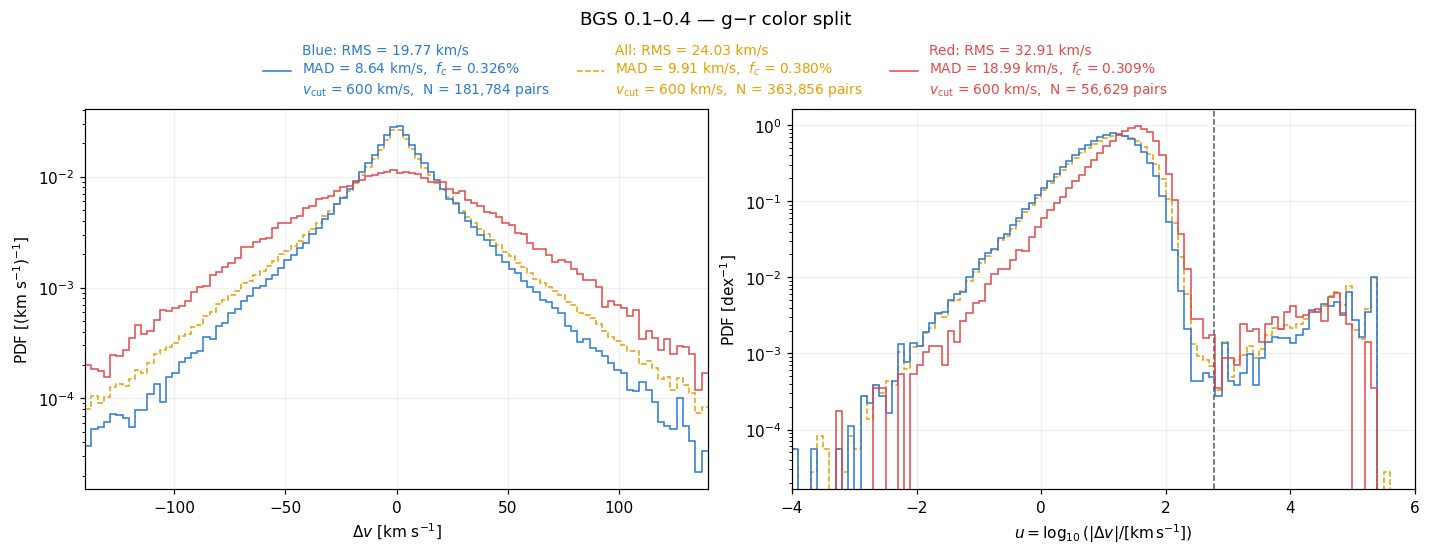

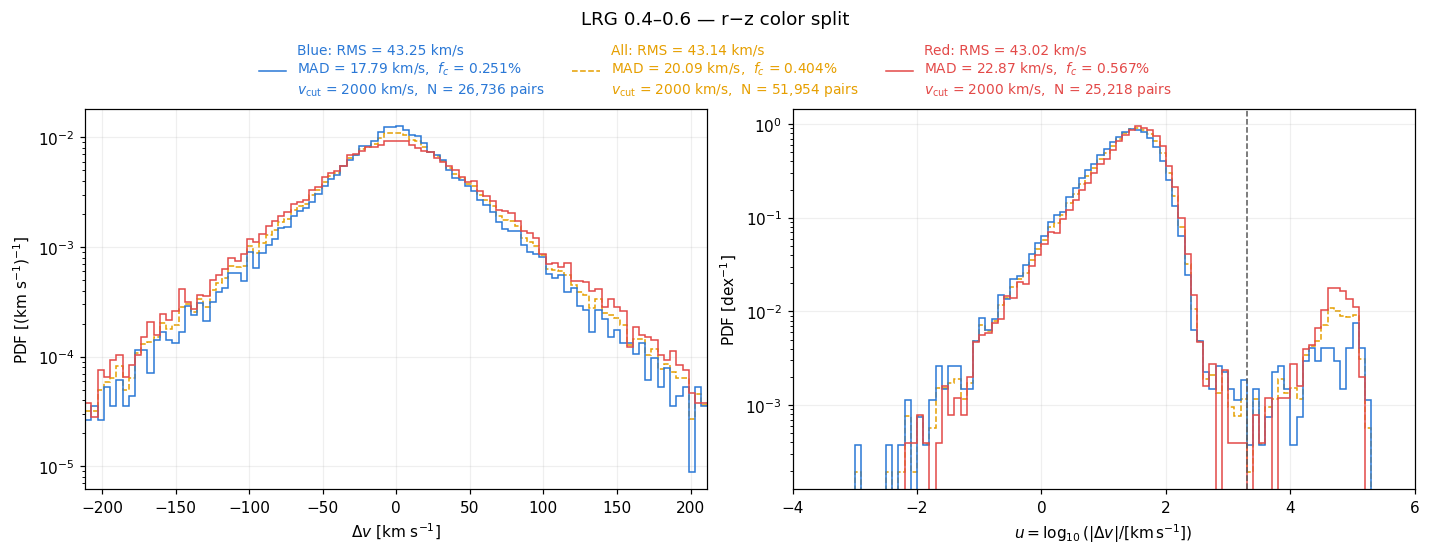

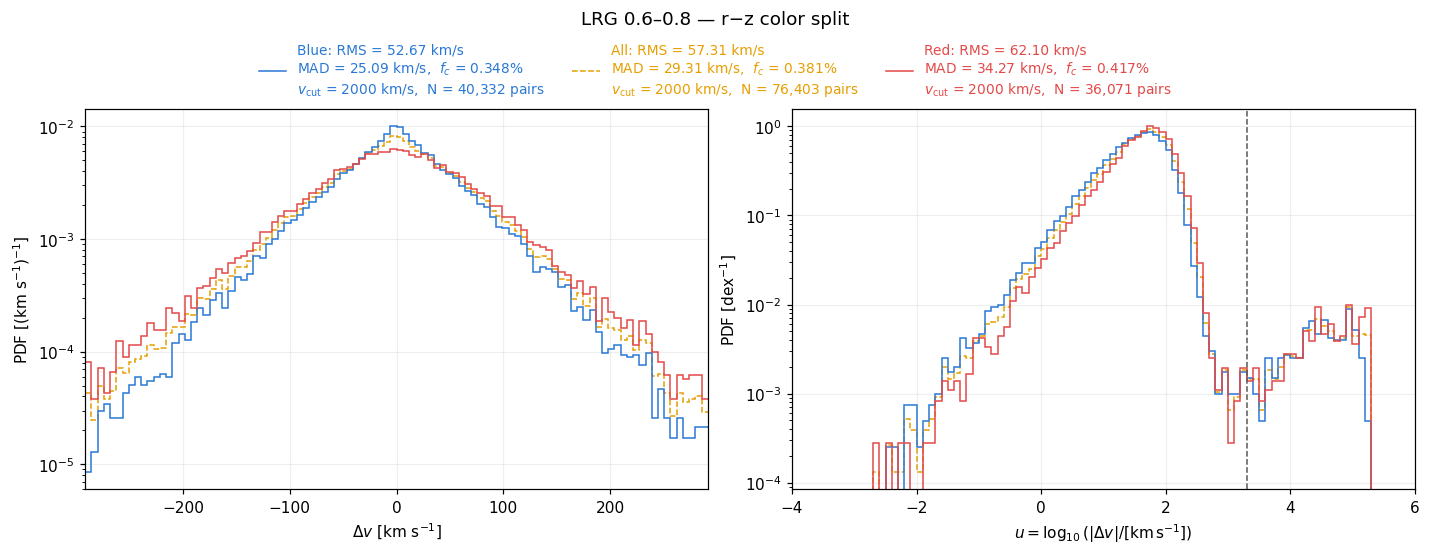

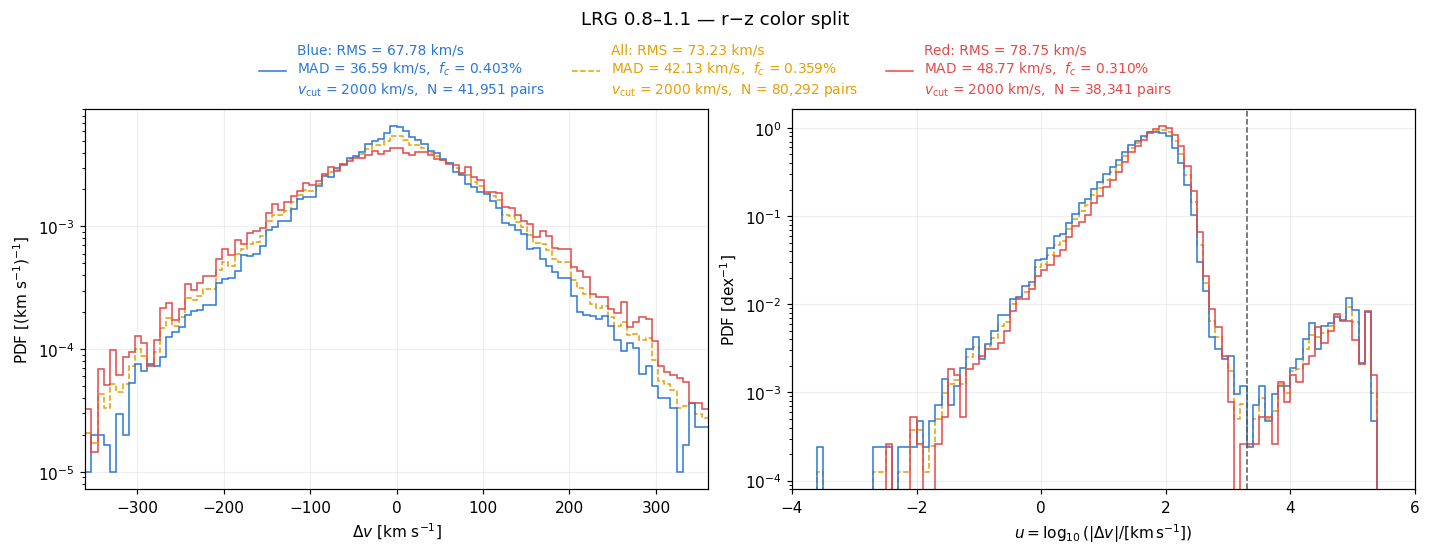

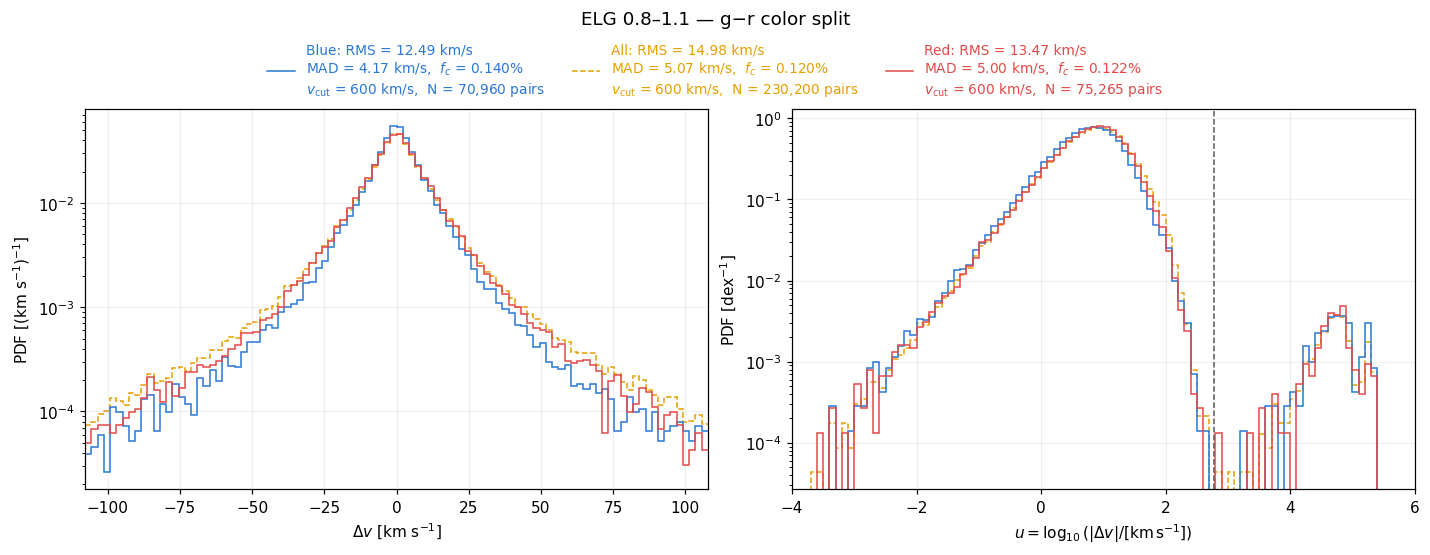

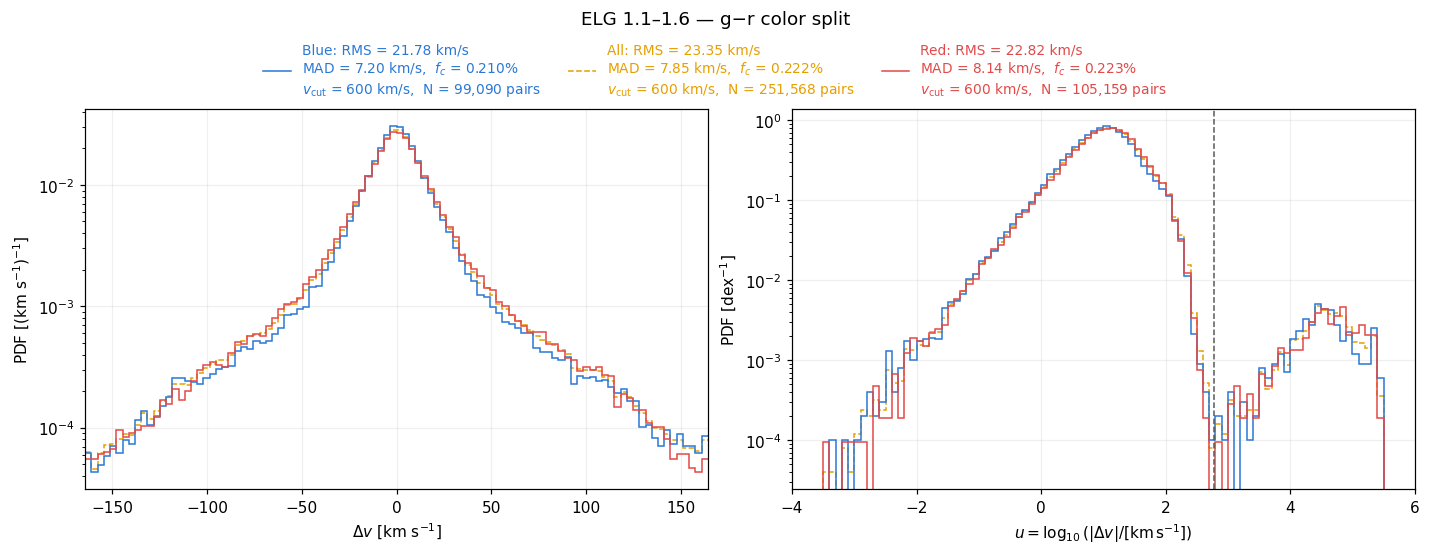

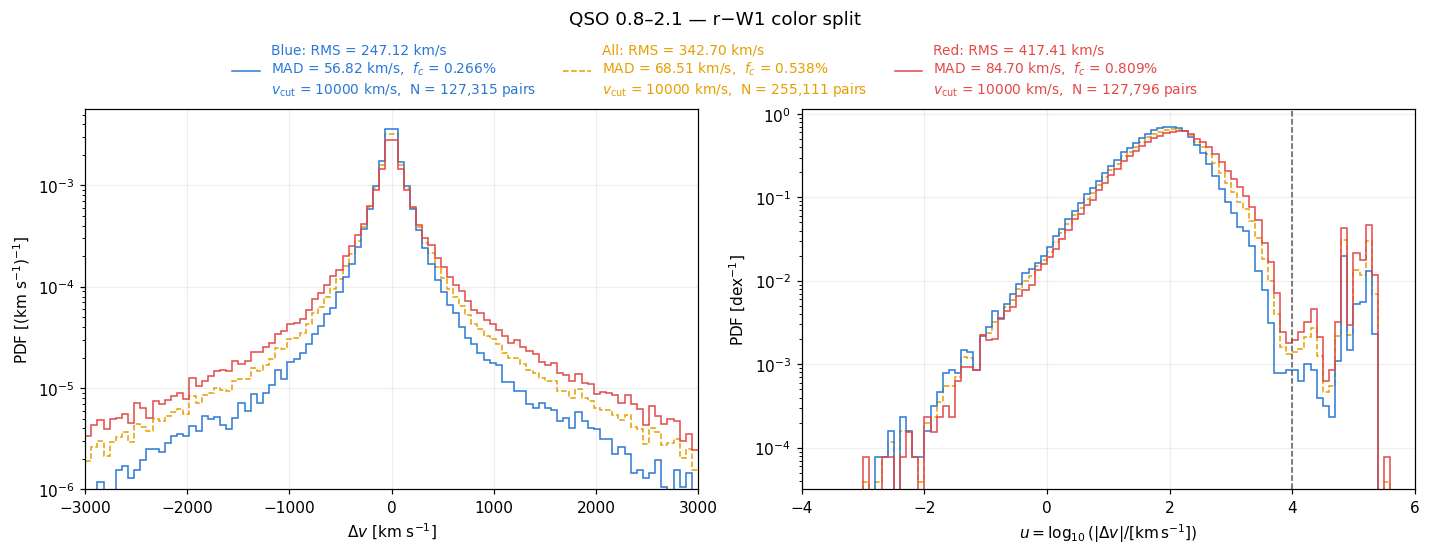

In [4]:
for name, sample in samples.items():
    halves, cthr = sample['halves'], sample['cthr']
    groups = {'blue': halves['blue'], 'full': sample['full'], 'red': halves['red']}
    combined = sample['full']['dv']
    if not len(combined):
        print(f'{name}: no selected pairs; skipping distribution plot')
        continue
    core = np.abs(combined[np.abs(combined) < cthr])
    central_limit = min(cthr, max(10., np.quantile(core, .995))) if len(core) else cthr
    limit = 3000. if sample['tracer'] == 'QSO' else central_limit
    linear_edges = np.linspace(-limit, limit, 101)
    positive = np.abs(combined[combined != 0])
    if len(positive):
        low = np.floor(np.log10(positive.min()) * 10) / 10 - .1
        high = np.ceil(np.log10(positive.max()) * 10) / 10 + .1
        log_edges = np.arange(low, high + .05, .1)
    else:
        log_edges = np.arange(-1., 1.05, .1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    metric_labels, legend_colors = [], []
    for color, h in groups.items():
        line_color = COLORS['repeat_all' if color == 'full' else f'repeat_{color}']
        line_style = '--' if color == 'full' else '-'
        group_label = 'All' if color == 'full' else color.capitalize()
        dv = h['dv']
        if not len(dv):
            continue
        linear_counts = np.histogram(dv, bins=linear_edges)[0]
        linear_pdf = linear_counts / (len(dv) * np.diff(linear_edges))
        outside = 1 - linear_counts.sum() / len(dv)
        np.testing.assert_allclose(np.sum(linear_pdf * np.diff(linear_edges)), 1 - outside)
        axes[0].stairs(linear_pdf, linear_edges, baseline=None, color=line_color, ls=line_style,
                       zorder=1 if color == 'full' else 2, label=group_label)
        absdv = np.abs(dv)
        nonzero = absdv > 0
        counts = np.histogram(np.log10(absdv[nonzero]), bins=log_edges)[0]
        hist = counts / (len(dv) * np.diff(log_edges))
        np.testing.assert_allclose(np.sum(hist * np.diff(log_edges)), nonzero.mean())
        nzero = int((~nonzero).sum())
        axes[1].stairs(hist, log_edges, color=line_color, ls=line_style,
                       zorder=1 if color == 'full' else 2, label=group_label)
        rms, mad, fc = h['estimate']
        annotation = (f'{group_label}: RMS = {rms:.2f} km/s\n'
                      + rf'MAD = {mad:.2f} km/s,  $f_c$ = {fc:.3f}%' + '\n'
                      + rf'$v_{{\rm cut}}$ = {cthr:g} km/s,  N = {len(dv):,} pairs')
        if nzero:
            annotation += f' ({nzero:,} zero differences)'
        metric_labels.append(annotation)
        legend_colors.append(line_color)
    axes[0].set(xlabel=r'$\Delta v$ [km s$^{-1}$]',
                ylabel=r'PDF [(km s$^{-1}$)$^{-1}$]', xscale='linear', yscale='log', xlim=(-limit, limit))
    axes[1].axvline(np.log10(cthr), color='.35', ls='--', lw=1)
    axes[1].set(xlabel=r'$u=\log_{10}(|\Delta v|/[\mathrm{km\,s^{-1}}])$',
                ylabel=r'PDF [dex$^{-1}$]', yscale='log', xlim=(-4, 6))
    if sample['tracer'] == 'QSO':
        axes[0].set_ylim(bottom=1e-6)
        axes[1].set_ylim(bottom=10**-4.5)
    fig.tight_layout(pad=.7)
    fig.subplots_adjust(top=.81)
    fig.suptitle(f'{name} — {sample["color_name"]} color split', y=.99)
    handles, _ = axes[0].get_legend_handles_labels()
    legend = fig.legend(handles, metric_labels, loc='upper center', bbox_to_anchor=(.5, .94),
                        ncol=3, frameon=False, fontsize=9, columnspacing=2, borderaxespad=0)
    for text, color in zip(legend.get_texts(), legend_colors):
        text.set_color(color)
    basename = f'{TAG}_{sample["tracer"]}_z{sample["zmin"]:g}-{sample["zmax"]:g}_dv'
    fig.savefig(OUTPUT_DIR / f'{basename}.png', dpi=160)
    fig.savefig(OUTPUT_DIR / f'{basename}.pdf')
    plt.show()
    plt.close(fig)

## RMS, MAD and catastrophic fractions by tracer bin

“Redshift error quantities -- color splits” shows blue, red and **all** metrics.
Gray diamonds use all finite repeat pairs in each bin, without photometry requirements.
The full value is computed from those pairs, not the arithmetic mean of the two color metrics.
Blue and red partition the full QSO/LRG sample; BGS/ELG retain unclassified pairs lacking photometry.
Error bars show **one standard deviation from 500 joint whole-target bootstrap resamples**.

The second figure (in a separate cell, ordered MAD, RMS, $f_c$) shows
\[
\frac{m_{\rm red}-m_{\rm blue}}{m_{\rm all}}.
\]
Numerator and denominator use the same bootstrap draws, preserving their covariance.
Zero or nonfinite full metrics give undefined (NaN) ratios; finite draw counts are saved. These are repeat-error
comparisons, not clustering fits or estimates of ΔA/f.


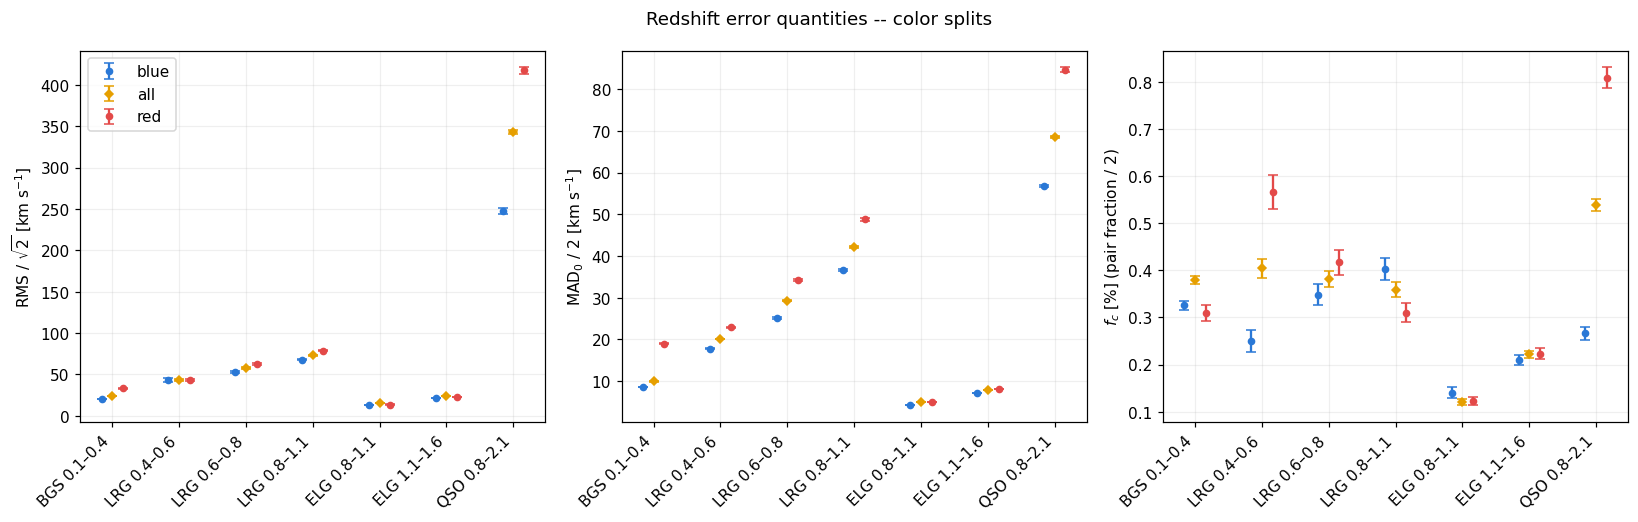

In [ ]:
labels = list(samples)
x = np.arange(len(labels))
ylabels = [r'RMS / $\sqrt{2}$ [km s$^{-1}$]', r'MAD$_0$ / 2 [km s$^{-1}$]', r'$f_c$ [%] (pair fraction / 2)']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for j, (metric, ylabel) in enumerate(zip(METRICS, ylabels)):
    for offset, color in [(-.16, 'blue'), (0., 'full'), (.16, 'red')]:
        frame = metrics[metrics['color'] == color].set_index('bin').reindex(labels)
        axes[j].errorbar(x + offset, frame[metric].to_numpy(dtype=float),
                         yerr=frame[f'{metric}_err'].to_numpy(dtype=float),
                         fmt='D' if color == 'full' else 'o', capsize=3, ms=4,
                         color=COLORS['repeat_all' if color == 'full' else f'repeat_{color}'],
                         label='all' if color == 'full' else color)
    axes[j].set_ylabel(ylabel)
    axes[j].set_xticks(x)
    axes[j].set_xticklabels(labels, rotation=45, ha='right')
axes[0].legend()
fig.suptitle('Redshift error quantities -- color splits')
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(OUTPUT_DIR / f'{TAG}_metrics.{ext}', dpi=160)
plt.show()
plt.close(fig)

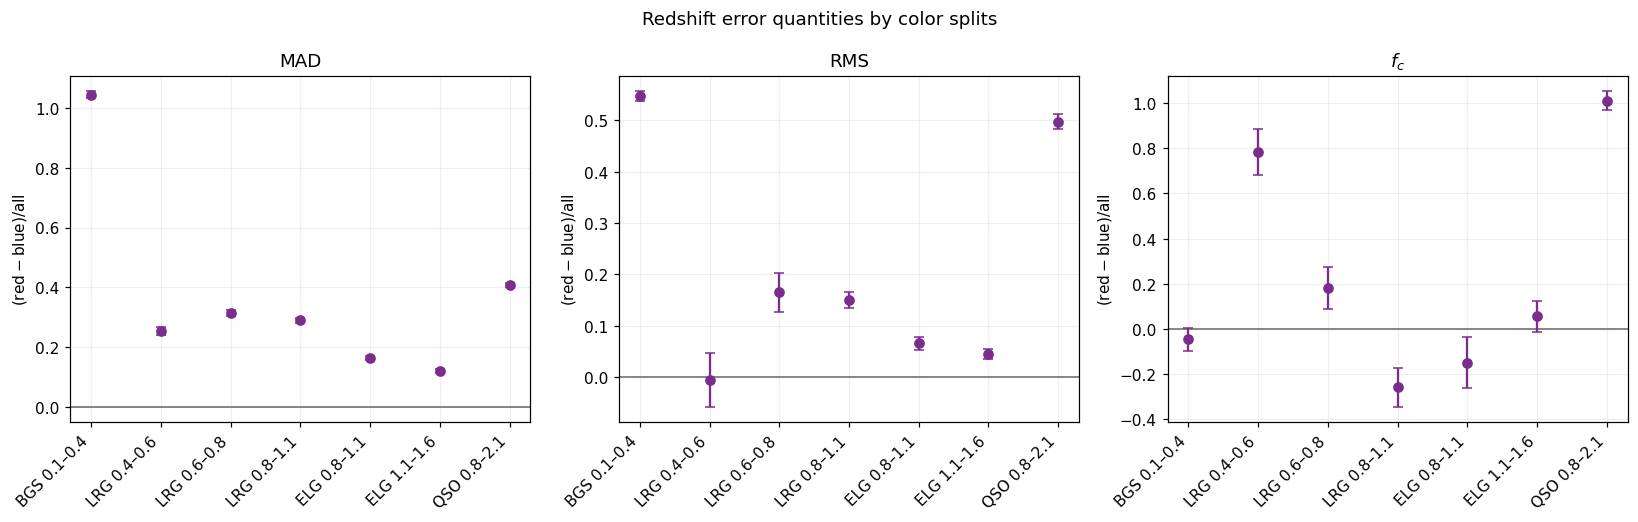

,bin,full_rms,relative_rms,relative_rms_err,n_bootstrap_rms,full_mad,relative_mad,relative_mad_err,n_bootstrap_mad,full_fc_percent,relative_fc_percent,relative_fc_percent_err,n_bootstrap_fc_percent
0,BGS 0.1–0.4,24.0291,0.5469,0.0093,500,9.9108,1.0446,0.0115,500,0.3797,-0.0445,0.0508,500
1,LRG 0.4–0.6,43.1372,-0.0054,0.0524,500,20.0895,0.2531,0.0121,500,0.4042,0.7829,0.0996,500
2,LRG 0.6–0.8,57.3149,0.1646,0.0380,500,29.3138,0.3131,0.0099,500,0.3809,0.1808,0.0922,500
3,LRG 0.8–1.1,73.2280,0.1498,0.0160,500,42.1288,0.2892,0.0091,500,0.3587,-0.2578,0.0853,500
4,ELG 0.8–1.1,14.9834,0.0652,0.0131,500,5.0740,0.1623,0.0075,500,0.1203,-0.1495,0.1126,500
5,ELG 1.1–1.6,23.3515,0.0447,0.0088,500,7.8453,0.1204,0.0064,500,0.2216,0.0568,0.0693,500
6,QSO 0.8–2.1,342.6995,0.4969,0.0147,500,68.5066,0.4069,0.0076,500,0.5384,1.0090,0.0420,500


Tables, provenance, PNG and PDF figures saved in /global/u1/s/shengyu/Y3/desi_y3_redshift_errors/main/repeat_obs/results/color_splits


In [6]:
labels = list(samples)
x = np.arange(len(labels))

def fractional_difference(red, blue, full):
    red, blue, full = (np.asarray(value, dtype=float) for value in (red, blue, full))
    valid = np.isfinite(red) & np.isfinite(blue) & np.isfinite(full) & (full != 0)
    return np.divide(red - blue, full, out=np.full_like(full, np.nan), where=valid)


relative_rows = []
for name, sample in samples.items():
    red, blue = sample['halves']['red'], sample['halves']['blue']
    full = sample['full']
    relative = fractional_difference(red['estimate'], blue['estimate'], full['estimate'])
    boot = fractional_difference(red['boot'], blue['boot'], full['boot'])
    row = dict(bin=name)
    for j, metric in enumerate(METRICS):
        row[f'full_{metric}'] = full['estimate'][j]
        row[f'relative_{metric}'] = relative[j]
        finite = boot[:, j][np.isfinite(boot[:, j])]
        row[f'relative_{metric}_err'] = np.std(finite, ddof=1) if len(finite) > 1 else np.nan
        row[f'n_bootstrap_{metric}'] = len(finite)
    relative_rows.append(row)
relative_differences = pd.DataFrame(relative_rows).set_index('bin').reindex(labels).reset_index()
relative_differences.to_csv(OUTPUT_DIR / f'{TAG}_relative_differences.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for j, (metric, title) in enumerate([('mad', 'MAD'), ('rms', 'RMS'), ('fc_percent', r'$f_c$')]):
    axes[j].axhline(0, color='.4', lw=1)
    axes[j].errorbar(x, relative_differences[f'relative_{metric}'].to_numpy(dtype=float),
                     yerr=relative_differences[f'relative_{metric}_err'].to_numpy(dtype=float),
                     fmt='o', capsize=3, color='#7b2d8e')
    axes[j].set_title(title)
    axes[j].set_ylabel(r'$(\mathrm{red}-\mathrm{blue})/\mathrm{all}$')
    axes[j].set_xticks(x)
    axes[j].set_xticklabels(labels, rotation=45, ha='right')
fig.suptitle('Redshift error quantities by color splits')
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(OUTPUT_DIR / f'{TAG}_differences.{ext}', dpi=160)
plt.show()
plt.close(fig)
display(relative_differences.round(4))
print(f'Tables, provenance, PNG and PDF figures saved in {OUTPUT_DIR}')


## Interpretation and reproducibility

- BGS/ELG have incomplete photometry coverage. Their full reference includes an unclassified
  component; QSO/LRG are completely partitioned by the direct color split.
- Multiple observations of one target produce correlated pairs, weighted equally here.
  Pair-mean redshifts can assign different colors to pairs of the same target. The joint
  target bootstrap keeps those pairs together across full, blue and red samples. Error bars
  do not account for threshold uncertainty or selection systematics.
- The saved threshold curves were derived from the narrower clustering samples (notably
  BGS_BRIGHT-21.35). Applying them to all photometrically eligible repeats extends their
  application; it does not guarantee equal-size halves or reproduce every saved target label.
- Colors, luminosity, redshift, S/N and observing conditions can be correlated. Differences
  establish associations, not their physical cause. Catastrophic pairs can affect the mean
  redshift used for their threshold; endpoint-held evaluations are counted in the coverage table.
- No repeat catalogs or external reference files are modified. Input hashes, interpolation,
  endpoint handling, and redshift choices are recorded in the provenance JSON. The threshold
  CSV records the reference samples used; `THRESHOLD_ROOT` identifies their source files.
